<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet4%20PBL/Tugas%20Praktikum%20JS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Tugas K-Means

1. Memuat dan Menggabungkan Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Membaca dataset cafes.csv dan reviews.csv
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Agregasi data review per kafe
review_agg = df_reviews.groupby('cafe_id').agg({'rating': ['mean', 'count'], 'likes': 'sum'})
review_agg.columns = ['avg_review_rating', 'total_reviews_scraped', 'total_likes']
review_agg = review_agg.reset_index()

# Menggabungkan dataframe
df = pd.merge(df_cafes, review_agg, on='cafe_id', how='left').fillna(0)
df.head()

,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query,avg_review_rating,total_reviews_scraped,total_likes
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang,4.400000,30.0,0.0
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang,4.866667,30.0,0.0
2,cb007499-1d5e-4613-8bbc-c0d30e17b2d2,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,['Kafe'],0888-8299-000,0,2026-10-11T13:55:10.909678,cafe Kota Malang,4.217391,23.0,0.0
3,f4cd572c-a98d-4309-aa81-6018d889c9d6,Zocco Heritage,"Jl. Raya Lawang - Malang No.34, Klojen, Purwan...",-7.967561,112.633346,4.3,701,['Kedai Kopi'],0,instagram.com,2026-10-11T13:55:27.732707,cafe Kota Malang,4.133333,30.0,0.0
4,fdd5baff-4477-4188-abf8-4f2a00cf10ee,RASWARA COFFEE AND EATERY,"Jl. Suropati No.1, Klojen, Kec. Klojen, Kota M...",-7.976481,112.634028,4.3,686,['Kafe'],0822-3131-2363,instagram.com,2026-10-11T13:55:43.558923,cafe Kota Malang,3.666667,30.0,0.0


2. Seleksi Fitur yang Tepat (Minimal 2 Fitur)

In [3]:
# Seleksi fitur
X = df[['rating', 'review_count']].values

# Normalisasi skala fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

3. Menentukan Jumlah $k$ Terbaik dengan Metode Elbow

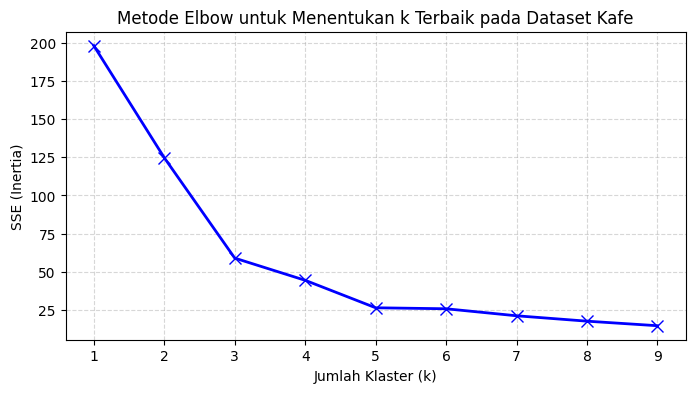

In [4]:
# Menghitung SSE untuk setiap nilai k
sse = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    sse.append(kmeans.inertia_)

# Plotting Metode Elbow
plt.figure(figsize=(8, 4))
plt.plot(K_range, sse, "bx-", linewidth=2, markersize=8)
plt.xlabel("Jumlah Klaster (k)")
plt.ylabel("SSE (Inertia)")
plt.title("Metode Elbow untuk Menentukan k Terbaik pada Dataset Kafe")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

4. Implementasi Model K-Means Final ($k = 3$) dan Visualisasi

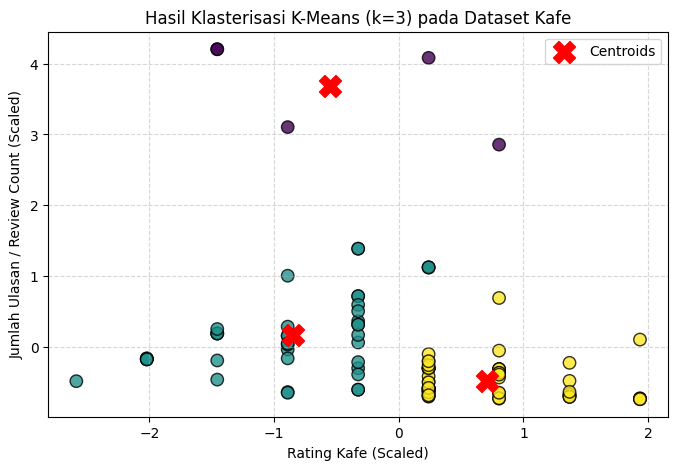

In [5]:
# Membuat model K-Means dengan k=3 terbaik
best_k = 3
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init='auto')
y_kmeans = kmeans_final.fit_predict(X_scaled)

# Plot Hasil Klasterisasi
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_kmeans, s=80, cmap='viridis', edgecolor='k', alpha=0.8)

# Plot Centroids
centers = kmeans_final.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, marker='X', label='Centroids')

plt.xlabel("Rating Kafe (Scaled)")
plt.ylabel("Jumlah Ulasan / Review Count (Scaled)")
plt.title(f"Hasil Klasterisasi K-Means (k={best_k}) pada Dataset Kafe")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Tugas DBSCAN

1. Pembuatan Dataset make_moons dan Normalisasi

In [6]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

# 1. Membuat dataset make_moons (1000 sampel, noise=0.05)
X_moon, y_true_moon = make_moons(n_samples=1000, noise=0.05, random_state=42)

# Normalisasi data
X_moon_scaled = StandardScaler().fit_transform(X_moon)

2. Menjalankan DBSCAN (eps=0.2, min_samples=5)

In [7]:
# 2. Menjalankan DBSCAN
db_moon = DBSCAN(eps=0.2, min_samples=5).fit(X_moon_scaled)
labels_moon = db_moon.labels_

n_clusters_moon = len(set(labels_moon)) - (1 if -1 in labels_moon else 0)
n_noise_moon = list(labels_moon).count(-1)

print(f"Estimasi Jumlah Klaster: {n_clusters_moon}")
print(f"Estimasi Jumlah Titik Noise: {n_noise_moon}")

Estimasi Jumlah Klaster: 2
Estimasi Jumlah Titik Noise: 0


3. Evaluasi Kualitas Klasterisasi

In [8]:
# 3. Evaluasi metrik kualitas klasterisasi
print(f"Homogeneity: {metrics.homogeneity_score(y_true_moon, labels_moon):.3f}")
print(f"Completeness: {metrics.completeness_score(y_true_moon, labels_moon):.3f}")
print(f"V-measure: {metrics.v_measure_score(y_true_moon, labels_moon):.3f}")
print(f"Adjusted Rand Index (ARI): {metrics.adjusted_rand_score(y_true_moon, labels_moon):.3f}")
print(f"Adjusted Mutual Information (AMI): {metrics.adjusted_mutual_info_score(y_true_moon, labels_moon):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X_moon_scaled, labels_moon):.3f}")

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index (ARI): 1.000
Adjusted Mutual Information (AMI): 1.000
Silhouette Coefficient: 0.391


4. Visualisasi Hasil DBSCAN

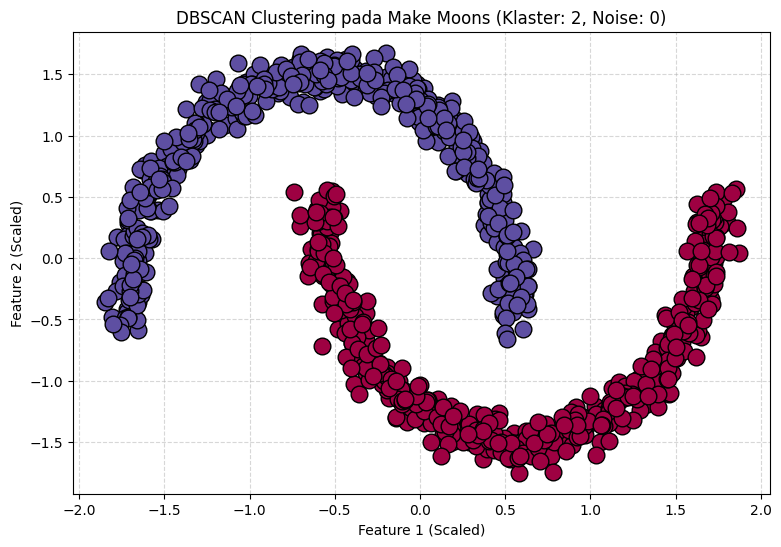

In [9]:
# 4. Visualisasi hasil klasterisasi DBSCAN
unique_labels = set(labels_moon)
core_samples_mask = np.zeros_like(labels_moon, dtype=bool)
core_samples_mask[db_moon.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(9, 6))
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Hitam untuk Noise / Outlier

    class_member_mask = (labels_moon == k)

    # Core samples (Titik besar)
    xy = X_moon_scaled[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col), markeredgecolor='k', markersize=12)

    # Non-core samples (Titik kecil)
    xy = X_moon_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col), markeredgecolor='k', markersize=5)

plt.title(f"DBSCAN Clustering pada Make Moons (Klaster: {n_clusters_moon}, Noise: {n_noise_moon})")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

5. Eksperimen Parameter (eps dan min_samples)

In [10]:
# 5. Eksperimen Parameter DBSCAN
eps_list = [0.05, 0.1, 0.3, 0.5]
min_samples_list = [3, 10, 20]

experiment_results = []

for eps in eps_list:
    for ms in min_samples_list:
        db_exp = DBSCAN(eps=eps, min_samples=ms).fit(X_moon_scaled)
        lbls = db_exp.labels_

        n_c = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_n = list(lbls).count(-1)
        sil = metrics.silhouette_score(X_moon_scaled, lbls) if n_c > 1 else -1
        ari = metrics.adjusted_rand_score(y_true_moon, lbls)

        experiment_results.append({
            'eps': eps,
            'min_samples': ms,
            'Clusters': n_c,
            'Noise': n_n,
            'Silhouette': round(sil, 3),
            'ARI': round(ari, 3)
        })

df_experiment = pd.DataFrame(experiment_results)
print(df_experiment.to_string(index=False))

 eps  min_samples  Clusters  Noise  Silhouette   ARI
0.05            3        69    186       0.113 0.030
0.05           10         3    970      -0.294 0.002
0.05           20         0   1000      -1.000 0.000
0.10            3         2     14       0.252 0.972
0.10           10         7     57       0.162 0.523
0.10           20         6    850      -0.360 0.017
0.30            3         2      0       0.391 1.000
0.30           10         2      0       0.391 1.000
0.30           20         2      0       0.391 1.000
0.50            3         2      0       0.391 1.000
0.50           10         2      0       0.391 1.000
0.50           20         2      0       0.391 1.000
